# **Part A. 군집화 복습과제 답안지**

**출제 의도**
- K-Means의 주요 파라미터를 이해하고 군집화를 수행할 수 있는가
- 학습 결과 속성을 활용하여 군집 중심과 이너셔를 확인할 수 있는가
- 개별·전체 실루엣 계수를 구분하고 해석할 수 있는가
- 여러 K의 결과를 비교하여 군집 개수의 후보를 설명할 수 있는가

**평가 항목**
- A-1. K-Means 모델 설정 및 학습 (10점)
- A-2. 군집 중심, 데이터 개수, 이너셔 (10점)
- A-3. 실루엣 계수와 음수 비율 (10점)
- A-4. K별 결과 비교와 해석 (10점)

> 배점은 A 파트 내 총 40점 기준의 예시입니다. 팀 전체 배점에 맞춰 조정할 수 있습니다. 명시한 필수 사용 조건을 충족하는 동등한 풀이도 인정합니다. 단순 군집 번호 차이와 미세한 부동소수점 차이는 감점하지 않습니다.

---

## **공통 준비**
### 실행해 주세요!
아래 셀은 수정하지 말고 먼저 실행해 주세요. NumPy, Matplotlib, scikit-learn이 필요합니다.

`X`는 네 개의 중심 주변에 생성한 2차원 합성 데이터입니다. `y_reference`는 생성 시 반환되는 참고 라벨이며, K-Means 학습과 실루엣 계산에는 사용하지 않습니다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

# 제공 코드: 모든 문항에서 공통으로 사용할 데이터
X, y_reference = make_blobs(
    n_samples=240,
    n_features=2,
    centers=[[-4, -4], [-4, 4], [4, -4], [4, 4]],
    cluster_std=0.8,
    random_state=17
)
print('X shape:', X.shape)


X shape: (240, 2)


## **A-1. 데이터를 네 개의 군집으로 나누어 주세요. (10점)**
가상 측정 데이터 `X`를 비슷한 특성을 가진 네 개의 그룹으로 나누려고 합니다.

K-Means 모델을 생성하여 `model_1`에 저장하고, 각 데이터의 군집 번호를 `labels_1`에 저장해 주세요.

**📌 조건**
- `KMeans`를 사용해 주세요.
- `n_clusters=4`, `init='k-means++'`, `n_init=10`, `random_state=17`로 설정해 주세요.
- `fit_predict(X)`를 이용하여 학습과 군집 할당을 수행해 주세요.
- 정답 참고 라벨 `y_reference`를 사용하지 마세요.

**💚 Test Case**
- 입력: 공통 준비 셀에서 생성한 `X`
- 출력:
```
데이터 개수: 240
군집 개수: 4
```

In [ ]:
### 예시 답안
# 군집 수와 초기화 관련 파라미터를 지정합니다.
model_1 = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=17)

# 정답 라벨 없이 X를 학습하고 군집 번호를 구합니다.
labels_1 = model_1.fit_predict(X)

# 결과 출력
print('데이터 개수:', len(labels_1))
print('군집 개수:', len(np.unique(labels_1)))

데이터 개수: 240
군집 개수: 4


---
**✅ 평가 기준**
- 모델 생성 및 네 가지 파라미터 설정 (4점, 각 1점)
- `fit_predict(X)`를 이용한 학습과 군집 할당 (3점)
- 군집 번호 배열을 `labels_1`에 저장 (1점)
- 결과를 올바르게 출력 (2점, 각 출력 1점)
---

**💡 해설**

`n_clusters`는 군집 수입니다. `k-means++`는 초기 중심이 서로 떨어지도록 선택하는 방식입니다. `n_init=10`은 초기화를 달리해 10회 실행한 결과 중 이너셔가 가장 작은 결과를 선택하도록 지정합니다. `random_state`는 난수 시드입니다.

`fit_predict(X)`는 데이터만으로 학습하고 각 데이터의 군집 번호를 반환합니다. 이 예제는 데이터가 240개이므로 군집 번호 배열의 길이도 240입니다. 0, 1, 2, 3은 군집 식별자이며 정답 클래스의 이름이 아닙니다.

## **A-2. 군집화 결과를 확인해 주세요. (10점)**
학습된 모델에서 군집 중심과 이너셔를 확인하고, 각 군집에 속한 데이터 개수를 계산하려고 합니다.

1. 중심 좌표를 `centers_2`에 저장해 주세요.
2. 군집 번호 순서대로 데이터 개수를 계산하여 `counts_2`에 저장해 주세요.
3. 이너셔를 `inertia_2`에 저장해 주세요.

**📌 조건**
- 제공된 `model_2`, `labels_2`를 사용해 주세요.
- 중심 좌표와 이너셔는 학습 후 생성된 모델 속성에서 가져와 주세요.
- `counts_2`는 군집 번호 0, 1, 2, 3에 대응하는 NumPy 배열이어야 합니다. `np.bincount()`를 활용할 수 있습니다.
- 결과값을 직접 입력하지 마세요.

**💚 Test Case**
- 입력: 제공 코드의 `model_2`, `labels_2`
- 출력:
```
군집 중심 형태: (4, 2)
군집별 데이터 개수: [60, 60, 60, 60]
전체 데이터 개수: 240
이너셔: 306.592
```
- 이너셔는 환경에 따라 소수점 끝자리가 조금 달라질 수 있습니다.

### 실행해 주세요!
아래 제공 코드는 수정하지 말아 주세요.

In [ ]:
# 제공 코드: A-1과 독립적으로 실행하기 위한 모델입니다.
model_2 = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=17)
labels_2 = model_2.fit_predict(X)

In [ ]:
### 예시 답안
# 학습 후 속성 이름의 끝에는 밑줄이 붙습니다.
centers_2 = model_2.cluster_centers_

# 각 군집 번호가 labels_2에 등장한 횟수를 셉니다.
counts_2 = np.bincount(labels_2, minlength=len(centers_2))

# 데이터와 소속 군집 중심 사이 거리의 제곱합입니다.
inertia_2 = model_2.inertia_

print('군집 중심 형태:', centers_2.shape)
print('군집별 데이터 개수:', counts_2.tolist())
print('전체 데이터 개수:', int(counts_2.sum()))
print(f'이너셔: {inertia_2:.3f}')

군집 중심 형태: (4, 2)
군집별 데이터 개수: [60, 60, 60, 60]
전체 데이터 개수: 240
이너셔: 306.592


### 결과 확인
아래 시각화 코드는 그대로 실행해 주세요.

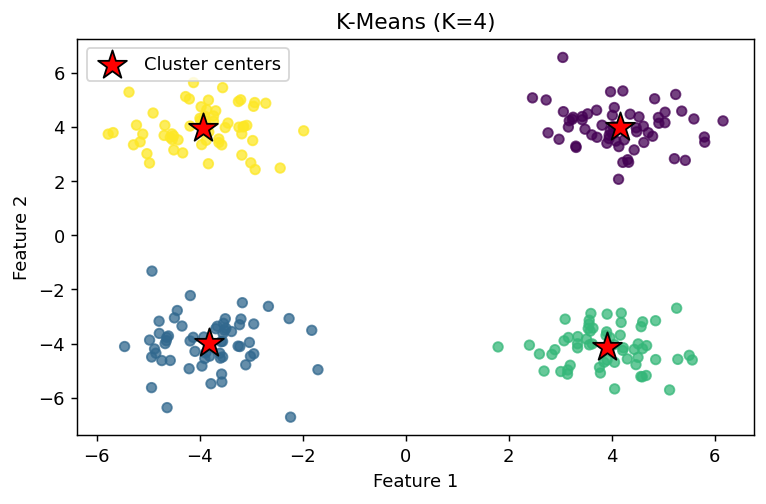

In [ ]:
# 제공 코드: 시각화는 따로 작성하지 않아도 됩니다.
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels_2, cmap='viridis', s=28, alpha=0.75)
plt.scatter(centers_2[:, 0], centers_2[:, 1], marker='*', s=280,
            c='red', edgecolors='black', label='Cluster centers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means (K=4)')
plt.legend()
plt.tight_layout()
plt.show()


---
**✅ 평가 기준**
- `cluster_centers_`에서 중심 좌표 추출 및 저장 (3점)
- `labels_2`로 군집 번호 순서의 데이터 개수 계산 및 저장 (3점)
- `inertia_`에서 이너셔 추출 및 저장 (2점)
- 결과 출력 (2점, 중심 형태·개수 합 확인 1점 / 개수 목록·이너셔 출력 1점)
---

**💡 해설**

`cluster_centers_`는 각 군집 중심의 좌표입니다. 군집이 네 개이고 특성이 두 개이므로 형태는 `(4, 2)`입니다. `np.bincount()`는 정수 값의 등장 횟수를 세므로 i번째 원소는 i번 군집의 데이터 개수입니다.

`inertia_`는 각 데이터와 자신이 속한 군집 중심 사이 거리의 제곱합입니다. 중심점들끼리의 거리 합이 아닙니다. 이 데이터의 이너셔는 약 306.592입니다.

이 예제에서는 네 군집이 각각 60개로 나뉘지만, 실제 데이터의 좋은 군집화가 반드시 같은 군집 크기를 의미하는 것은 아닙니다. 아래 그래프에서 작은 점은 데이터, 빨간 별표는 학습한 중심입니다.

## **A-3. 실루엣 계수로 군집화 결과를 평가해 주세요. (10점)**
전체 데이터가 군집에 얼마나 적절하게 할당되었는지 확인하려고 합니다.

1. 각 데이터의 실루엣 계수를 `sample_scores_3`에 저장해 주세요.
2. 전체 평균 실루엣 계수를 `mean_score_3`에 저장해 주세요.
3. 계수가 0 미만인 데이터의 비율을 `negative_ratio_3`에 저장해 주세요.

**📌 조건**
- 개별 계수에는 `silhouette_samples()`, 전체 평균에는 `silhouette_score()`를 사용해 주세요.
- 두 함수에 `X`와 예측 군집 번호인 `labels_3`를 입력해 주세요.
- 음수 비율은 개수를 전체 데이터 수로 나눈 0~1의 값으로 저장해 주세요.
- 0인 데이터는 음수 개수에 포함하지 않습니다.

**💚 Test Case**
- 입력: `X`, 제공 코드의 `labels_3`
- 출력:
```
개별 계수 배열 형태: (240,)
전체 평균 실루엣 계수: 0.8098
개별 계수 평균과 일치: True
음수인 데이터 비율: 0.00%
```
- 실루엣 계수는 환경에 따라 소수점 끝자리가 조금 달라질 수 있습니다.

### 실행해 주세요!
아래 제공 코드는 수정하지 말아 주세요.

In [ ]:
# 제공 코드: 앞 문항을 풀지 못해도 실루엣 평가를 할 수 있습니다.
model_3 = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=17)
labels_3 = model_3.fit_predict(X)

In [ ]:
### 예시 답안
sample_scores_3 = silhouette_samples(X, labels_3)
mean_score_3 = silhouette_score(X, labels_3)

# True는 1, False는 0으로 처리되므로 평균이 음수 데이터의 비율입니다.
negative_ratio_3 = np.mean(sample_scores_3 < 0)

print('개별 계수 배열 형태:', sample_scores_3.shape)
print(f'전체 평균 실루엣 계수: {mean_score_3:.4f}')
print('개별 계수 평균과 일치:', bool(np.isclose(mean_score_3, sample_scores_3.mean())))
print(f'음수인 데이터 비율: {negative_ratio_3:.2%}')

개별 계수 배열 형태: (240,)
전체 평균 실루엣 계수: 0.8098
개별 계수 평균과 일치: True
음수인 데이터 비율: 0.00%


---
**✅ 평가 기준**
- `silhouette_samples(X, labels_3)`를 사용하여 개별 계수 저장 (3점)
- `silhouette_score(X, labels_3)`를 사용하여 전체 평균 저장 (3점)
- 0 미만인 데이터 비율 계산 (2점)
- 결과 출력 (2점, 형태·평균 1점 / 일치 여부·비율 1점)
---

**💡 해설**

`silhouette_samples()`는 각 데이터의 점수 배열을, `silhouette_score()`는 전체 평균을 반환합니다. 두 함수 모두 정답 라벨이 아닌 학습한 군집 번호를 사용합니다.

실루엣 계수의 범위는 -1~1입니다. 1에 가까우면 자신의 군집과 가깝고 다른 군집과 잘 분리되어 있습니다. 0 부근은 소속이 모호한 경계일 수 있습니다. 음수는 자신이 속한 군집보다 다른 군집의 데이터들과 평균적으로 더 가깝다는 의미입니다.

`np.mean(sample_scores_3 < 0)` 대신 `np.sum(sample_scores_3 < 0) / len(sample_scores_3)`도 가능합니다. 이 예제에서는 평균 약 0.8098, 음수 비율 0%가 나옵니다. 전체 평균만으로 단정하지 말고 군집별 점수 분포도 함께 살펴보아야 합니다.

## **A-4. 적절한 군집 개수의 후보를 찾아 주세요. (10점)**
K를 1~8로 바꾸어 학습하고, 이너셔와 실루엣 계수를 비교하려고 합니다.

### **A-4-1. 코드 작성 (7점)**
- 각 K의 이너셔를 `inertias`에 순서대로 저장해 주세요.
- 각 K의 평균 실루엣 계수를 `scores`에 순서대로 저장해 주세요.

**📌 조건**
- `for`문을 사용해 `k_values`를 순회해 주세요.
- 각 K에 대해 새로운 `KMeans` 모델을 생성해 주세요.
- `init='k-means++'`, `n_init=10`, `random_state=17`을 모든 모델에 동일하게 지정해 주세요.
- K=1이면 실루엣 계수는 정의되지 않습니다. 해당 함수는 호출하지 않고 `scores`에 `np.nan`을 넣어 주세요.
- 나머지 K에서는 예측한 군집 번호로 평균 실루엣 계수를 계산해 주세요.
- K=1의 이너셔도 계산해야 하며, 각 리스트의 길이는 8이어야 합니다.

**💚 Test Case**
- 입력: `X`, `k_values = [1, 2, 3, 4, 5, 6, 7, 8]`
- 출력 예시:
```
K=1: inertia=7947.534, silhouette=계산 불가
K=2: inertia=4063.434, silhouette=0.5121
K=3: inertia=2094.031, silhouette=0.6220
K=4: inertia=306.592, silhouette=0.8098
K=5: inertia=276.895, silhouette=0.6837
K=6: inertia=248.347, silhouette=0.5614
K=7: inertia=223.046, silhouette=0.4440
K=8: inertia=197.594, silhouette=0.3351
```
- 값은 실행 환경에 따라 조금 달라질 수 있습니다. 그래프를 그리는 코드는 제공합니다.

In [ ]:
### 예시 답안
k_values = list(range(1, 9))
inertias = []
scores = []

for k in k_values:
    model_k = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=17)
    labels_k = model_k.fit_predict(X)
    inertias.append(model_k.inertia_)

    # 군집이 하나이면 다른 군집과의 거리를 계산할 수 없습니다.
    if k == 1:
        scores.append(np.nan)
    else:
        scores.append(silhouette_score(X, labels_k))

# 아래 출력 코드는 수정하지 말아 주세요.
for k, inertia_value, score in zip(k_values, inertias, scores):
    score_text = '계산 불가' if np.isnan(score) else f'{score:.4f}'
    print(f'K={k}: inertia={inertia_value:.3f}, silhouette={score_text}')

K=1: inertia=7947.534, silhouette=계산 불가
K=2: inertia=4063.434, silhouette=0.5121
K=3: inertia=2094.031, silhouette=0.6220
K=4: inertia=306.592, silhouette=0.8098
K=5: inertia=276.895, silhouette=0.6837
K=6: inertia=248.347, silhouette=0.5614
K=7: inertia=223.046, silhouette=0.4440
K=8: inertia=197.594, silhouette=0.3351


### 결과 확인
아래 코드는 수정하지 말고 실행해 주세요.

평균 실루엣 계수가 가장 높은 K: 4


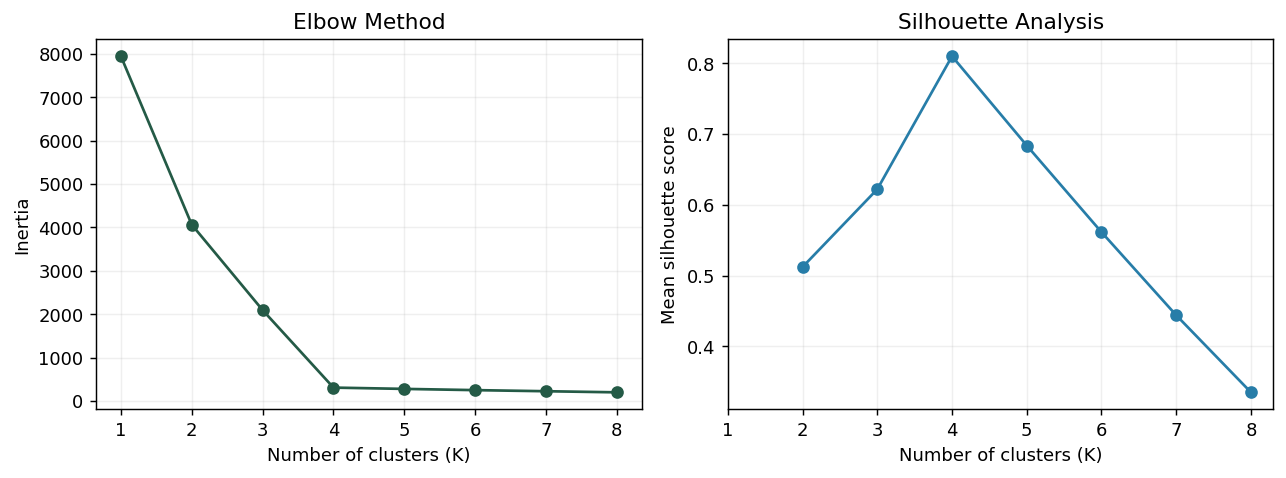

In [ ]:
# 제공 코드: 그래프를 확인하고 해석 문항에 답하세요.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(k_values, inertias, 'o-', color='#245A46')
axes[0].set(title='Elbow Method', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(k_values, scores, 'o-', color='#277DA8')
axes[1].set(title='Silhouette Analysis', xlabel='Number of clusters (K)',
            ylabel='Mean silhouette score')
for ax in axes:
    ax.set_xticks(k_values)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

best_k = k_values[int(np.nanargmax(scores))]
print('평균 실루엣 계수가 가장 높은 K:', best_k)


### **A-4-2. 결과 해석 (3점)**
위 결과와 그래프를 보고 다음 질문에 각각 답해 주세요.

1. 평균 실루엣 계수를 기준으로 선택할 K는 무엇인가요?
2. 엘보 그래프에서 이너셔 감소 폭이 크게 줄어드는 K는 무엇인가요?
3. 이너셔가 가장 작은 K를 무조건 선택하면 안 되는 이유를 1~2문장으로 설명해 주세요.

**💡 예시 답안**
1. **K=4**입니다. 비교한 K 중 평균 실루엣 계수가 약 0.8098로 가장 높습니다.
2. **K=4**입니다. K=4까지 이너셔가 크게 감소하고 이후부터 감소 폭이 작아집니다.
3. K가 커지면 더 많은 중심으로 데이터를 표현해 이너셔가 작아지는 경향이 있습니다. 최솟값만 고르면 군집을 불필요하게 잘게 나눌 수 있어, 감소 폭·실루엣 점수·활용 목적을 함께 고려해야 합니다.

---
**✅ 평가 기준**
- **A-4-1. 코드 작성 (7점)**
  - for문으로 8개 K를 순회하며 새 모델 생성·학습 (4점: 순회 1점 / K 반영 1점 / 공통 파라미터 설정 1점 / 학습 1점)
  - K 순서대로 이너셔를 저장 (1점)
  - K=1에서 실루엣 함수 호출 없이 np.nan 저장 (1점)
  - 나머지 K의 실루엣 계수를 올바르게 저장 (1점)
- **A-4-2. 결과 해석 (3점)**
  - 실루엣 기준 K=4 제시 (1점)
  - 엘보 후보 K=4 제시 (1점)
  - K 증가 시 이너셔가 작아지는 경향을 근거로 선택의 한계를 설명 (1점)
---

**💡 해설**

같은 데이터에서 군집 수만 바꾸어 비교해야 합니다. 각 K마다 모델을 새로 만들고, 그 모델의 군집 번호로 실루엣 계수를 계산합니다.

실루엣 계수는 군집 수가 2개 이상이고 데이터 개수보다 적을 때 정의됩니다. K=1에서는 다른 군집과의 평균 거리를 계산할 수 없습니다. 0은 실제로 가능한 실루엣 점수이므로, 계산 불가와 구분하기 위해 np.nan을 저장합니다.

이너셔는 K=3의 약 2094.031에서 K=4의 약 306.592로 크게 줄지만, K=5에서는 약 276.895로 감소 폭이 작아집니다. 실루엣 평균도 K=4에서 가장 높으므로 이 합성 데이터에서는 두 방법이 같은 후보를 제시합니다. 실제 데이터에서는 두 지표가 일치하지 않을 수 있으며, 엘보 지점이 뚜렷하지 않을 수도 있습니다.

`np.nanargmax(scores)`는 np.nan을 제외한 최댓값 위치를 찾아줍니다. 반환값은 리스트의 위치이므로 `k_values`에서 해당 위치의 K를 가져옵니다.

# **Part B: 평균 이동, GMM, DBSCAN**

#### 문제 3: 평균 이동(Mean Shift) 군집화의 이해

##### 3-1. Mean Shift 알고리즘은 KMeans와 유사하게 거리 기반 군집화 방법 중 하나입니다. `make_blobs`를 사용하여 가상의 데이터셋을 생성한 후 `MeanShift`를 적용하여 군집화를 수행하세요.

**데이터 생성시 parameter 설정**
  - n_samples=400
  - n_features=2
  - centers=3
  - cluster_std=0.8
  - random_state=0
  - 대역폭은 1로 설정

In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import MeanShift

X,y=make_blobs(n_samples=400, n_features=2, centers=3, cluster_std=0.8, random_state=0)

meanshift=MeanShift(bandwidth=1)
cluster_labels=meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

cluster labels 유형: [0 1 2]


##### 3-2. 최적의 bandwidth를 찾는 함수를 이용해 최적화된 bandwidth값을 적용하시오

In [ ]:
from sklearn.cluster import estimate_bandwidth
import pandas as pd

best_bandwidth = estimate_bandwidth(X) #파라미터로 피처데이터세트 입력
print('bandwidth 값:', round(best_bandwidth,3))

clusterDF=pd.DataFrame(data=X,columns=['ftr_x','ftr_y'])
clusterDF['target']=y

meanshift=MeanShift(bandwidth=best_bandwidth)
cluster_labels=meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

bandwidth 값: 1.981
cluster labels 유형: [0 1]



##### 3-3. '3-2'에서 군집화된 결과를 시각화하시오

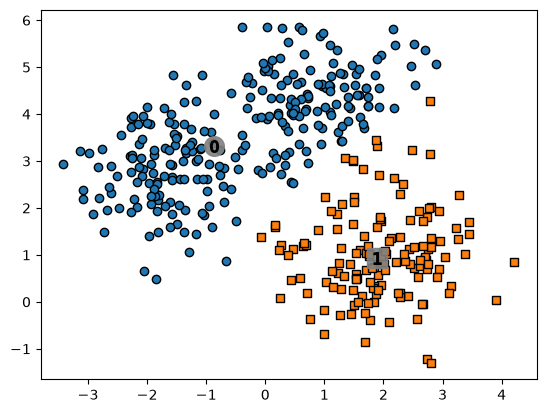

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

clusterDF['meanshift_label']=cluster_labels
centers= meanshift.cluster_centers_ #각 군집의 중심 좌표(행이 3개)
unique_labels= np.unique(cluster_labels)
markers=['o','s','^','x','*']

for label in unique_labels:
  label_cluster=clusterDF[clusterDF['meanshift_label']==label]
  center_x_y=centers[label]

  #군집별로 다른 마커로 산점도 적용
  plt.scatter(x=label_cluster['ftr_x'], y=label_cluster['ftr_y'], edgecolors='k', marker=markers[label])

  #군집별 중심 표현
  plt.scatter(x=center_x_y[0], y=center_x_y[1] ,s=200,color='gray',alpha=0.9, marker=markers[label])
  plt.scatter(x=center_x_y[0], y=center_x_y[1] ,s=70, color='k',edgecolor='k', marker='$%d$'%label)


plt.show()

#### 문제 4: GMM(Gaussian Mixture Model) 군집화의 이해

##### 4-1. GMM은 각 군집이 가우시안 분포를 따른다고 가정하는 확률 기반 군집화 알고리즘입니다. 다음 각 문항에 답하세요.

4-1-1. GMM의 EM 알고리즘을 적용할 때 사용하는 사이킷런 클래스와 주요 파라미터를 작성하시오.

답:

사이킷런 클래스: GaussianMixture
해당 클래스의 주요 파라미터는 n_component이며, 이는 가우시안 분포(혼합 성분)의 개수를 뜻한다.

4-1-2. GMM과 K-평균의 주요 차이점을 서술하시오.

답:

K-Means는 데이터 간의 거리를 기반으로 군집화를 수행하며, 데이터가 원형에 가까운 형태일수록 군집화 성능이 좋다. 비교적 적은 시간으로 수행할 수 있다는 장점이 있지만, 데이터가 타원형으로 길게 늘어진 경우 군집화 효율이 떨어질 수 있다.

반면 GMM은 확률을 기반으로 군집화를 수행하며, 데이터가 원형인 경우뿐만 아니라 비원형 데이터 등 다양한 형태의 데이터에서도 군집화를 수행할 수 있다. 다만 K-Means에 비해 수행 시간이 오래 걸린다는 단점이 있다.

#### 4-2. 군집 시각화 함수를 완성하고, `make_blobs`로 생성된 데이터에 `GaussianMixture`를 적용하여 군집화를 수행하고 시각화하세요.

**데이터 생성 시 조건**
- 샘플 수: 400개
- 군집 수 : 3개
- 특징 수: 2개
- 랜덤 시드: 0
- 군집별 표준편차 : 0.9
- 행렬 변환(transformaion)을 적용하여 길게 늘어난 타원형 분포를 갖도록 합니다.

**GMM 설정:**
- 가우시안 분포의 개수 : 3개
- 랜덤 시드: 0

In [ ]:
# 군집 시각화 함수

def visualize_cluster_plot(clusterobj, dataframe, label_name, iscenter=True):
    import matplotlib.pyplot as plt
    import numpy as np
    if iscenter:
        centers = clusterobj.cluster_centers_
    unique_labels = np.unique(dataframe[label_name].values)
    markers=['o', 's', '^', 'x', '*']
    isNoise=False

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name]==label]
        if label == -1:
            cluster_legend = 'Noise'
            isNoise=True
        else:
            cluster_legend = 'Cluster ' + str(label)
        plt.scatter(x=label_cluster['ftr_x'], y=label_cluster['ftr_y'], s=70, edgecolor='k', marker=markers[label], label=cluster_legend)

        if iscenter:
            center_x_y = centers[label]
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=250, color='white', alpha=0.9, edgecolor='k', marker=markers[label])
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k', marker='$%d$' % label)
    plt.legend(loc='upper right')
    plt.show()

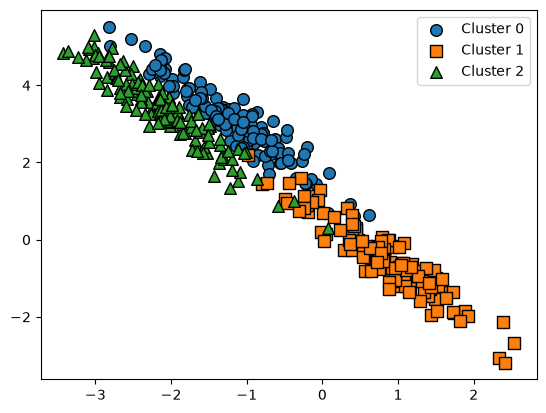

In [ ]:
#데이터 생성

from sklearn.datasets import make_blobs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X,y= make_blobs(n_samples=400 , n_features=2, centers=3, cluster_std=0.9, random_state=0)

#길게 늘어난 타원형의 데이터 세트를 생성하기 위해 변환
transformation =[[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)

#feature 데이터 세트와 make_bolbs()의 y결과값을 DataFrame으로 저장
clusterDF = pd.DataFrame(data=X_aniso, columns=['ftr_x', 'ftr_y'])
clusterDF['target']=y

#생성된 데이터 세트를 target별로 다른 마커로 표시해 시각화함
visualize_cluster_plot(None,clusterDF,'target',iscenter=False)

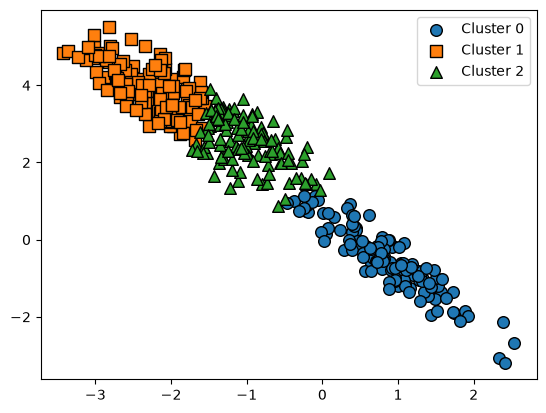

In [ ]:
# 군집화 수행 후 시각화
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=0)
gmm_label= gmm.fit(X_aniso).predict(X_aniso)
clusterDF['gmm_label'] = gmm_label

visualize_cluster_plot(gmm, clusterDF, 'gmm_label', iscenter=False)

#### 문제 5. DBSCAN을 이용한 군집화의 이해

##### 5-1. DBSCAN은 밀도 기반 군집화 방법으로, 군집의 개수를 미리 지정할 필요가 없으며 다양한 형태의 군집을 찾을 수 있는 알고리즘입니다. 다음 물음에 답하세요.

5-1-1. `make_moons`를 사용하여 초승달 모양 데이터셋을 생성한 후 `Kmeans`, `GMM`, `DBSCAN`을 적용하여 군집화를 수행하고 결과를 시각화하세요.

**데이터 생성 조건:**
- 샘플 수: 300개
- 군집 수: 2개
- 특징 수: 2개
- 노이즈 수준: 0.05
- 랜덤 시드: 42

**K-Means 모델 설정 조건**
- 군집 수: 2개
- 최대 반복 횟수: 1,000회
- 랜덤 시드: 42

**GMM 모델 설정 조건**
- 가우시안 분포의 개수: 2개
- 최대 반복 횟수: 1,000회
- 랜덤 시드: 42

**DBSCAN 모델 설정 조건**
- 반경(eps): 0.2
- 최소 샘플 수(min_samples): 8개
- 거리 측정 방식: 유클리드 거리(Euclidean distance)


 풀이 : 각 조건에 따르면, 다음과 같이 코드를 완성하여 아래 문항에 답할 수 있다.

- X,y=make_moons(n_samples=300,shuffle=True,noise=0.05,random_state=42)
- kmeans= KMeans(n_clusters=2, max_iter= 1000, random_state=42)
- gmm= GaussianMixture(n_components=2, max_iter= 1000, random_state=42)
- dbscan = DBSCAN(eps=0.2, min_samples=8,metric='euclidean')


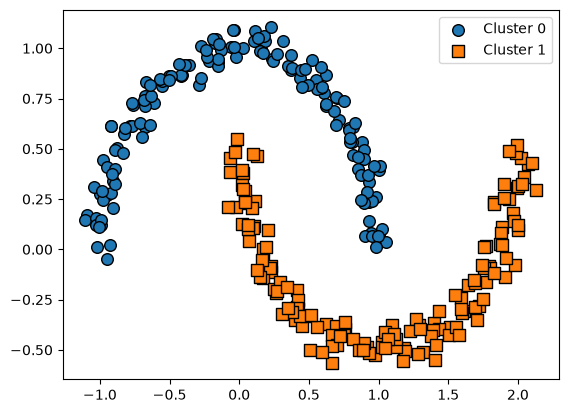

In [ ]:
#데이터셋 생성
import pandas as pd
from sklearn.datasets import make_moons

X,y=make_moons(n_samples=300,shuffle=True,noise=0.05,random_state=42)
clusterDF=pd.DataFrame(data=X,columns=['ftr_x','ftr_y'])
clusterDF['target']=y

#데이터셋 시각화
visualize_cluster_plot(None,clusterDF,'target',iscenter=False)

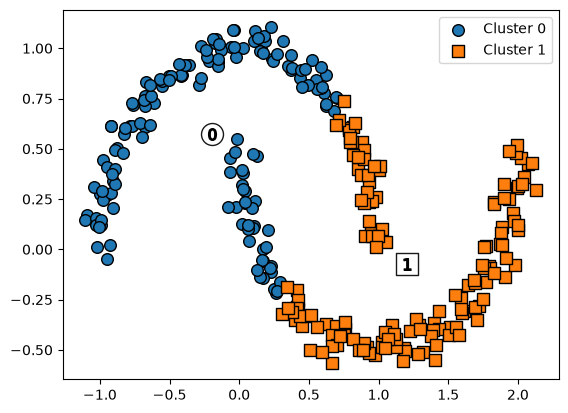

In [ ]:
#Kmeans로 make_circles() 데이터 세트를 군집화 수행
from sklearn.cluster import KMeans

kmeans= KMeans(n_clusters=2, max_iter= 1000, random_state=42)
kmeans_labels= kmeans.fit_predict(X)
clusterDF['kmeans_cluster']= kmeans_labels

#군집화 결과 시각화
visualize_cluster_plot(kmeans, clusterDF, 'kmeans_cluster', iscenter=True)

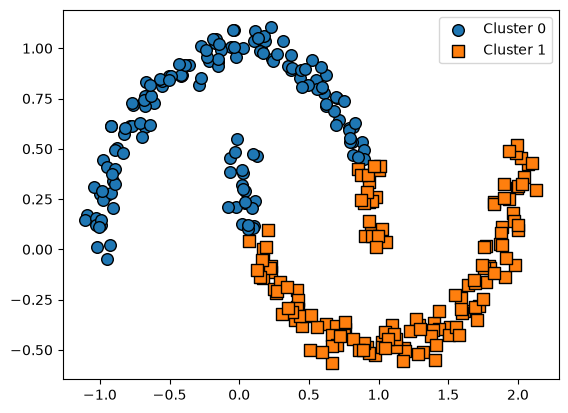

In [ ]:
#GMM으로 make_circles() 데이터 세트 군집화 수행
from sklearn.mixture import GaussianMixture

gmm= GaussianMixture(n_components=2, max_iter= 1000, random_state=42)
gmm_labels= gmm.fit_predict(X)
clusterDF['gmm_cluster']= gmm_labels

#군집화 결과 시각화
visualize_cluster_plot(gmm, clusterDF, 'gmm_cluster', iscenter=False)

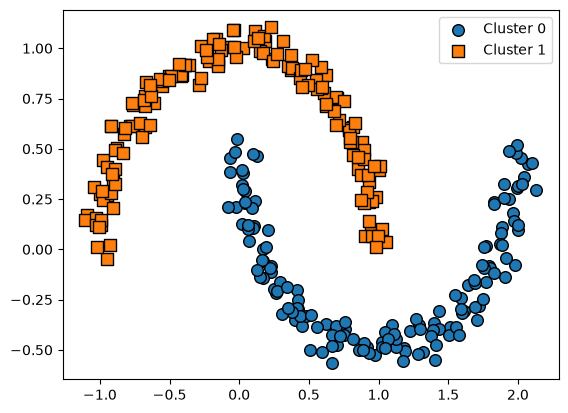

In [ ]:
# DBSCAN으로 make_circles( ) 데이터 셋 군집화 수행
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=8,metric='euclidean')
dbscan_labels = dbscan.fit_predict(X)
clusterDF['dbscan_cluster'] = dbscan_labels


#군집화 결과 시각화
visualize_cluster_plot(dbscan, clusterDF, 'dbscan_cluster', iscenter=False)

5-1-2. 앞서 수행한 세 알고리즘의 군집화 결과를 비교하고, 복잡한 기하학적 분포를 가진 데이터에서 가장 적합한 알고리즘을 선택하시오. 그 이유를 함께 서술하시오.

답 :  세 알고리즘의 군집화 결과를 비교하면 다음과 같다.

1. K-Means: 두 개의 군집으로 구분하였으나, 초승달 형태의 비선형적인 분포를 제대로 반영하지 못하고 일부 데이터가 잘못 분류되었다.

2. GMM: 두 개의 가우시안 분포를 기반으로 군집을 형성하였으나, 역시 복잡한 초승달 형태의 분포를 정확하게 구분하지 못하였다.

3. DBSCAN: 데이터의 밀도를 기반으로 군집을 형성하여 초승달 형태의 비선형적인 분포를 비교적 정확하게 구분하였다.

복잡한 기하학적 분포의 데이터에서 가장 적합한 알고리즘은 DBSCAN이다.

 이유: DBSCAN은 밀도 기반 군집화 알고리즘으로, 군집의 형태에 대한 제약이 적어 초승달 모양과 같은 복잡한 비선형 구조의 데이터도 효과적으로 군집화할 수 있다. 반면 K-Means와 GMM은 이러한 비선형적인 군집 구조를 파악하는 데 한계가 있다.

# 11주차 복습과제 — 7장 군집화 (C파트: 병합 군집 · 고객 세그먼테이션)

- 문항 수: 4문항 (C파트 담당 범위)
- 제출: 각 문항 아래 빈 code 셀에 풀이를 작성하고, 필요한 결과는 출력하세요.
- 사용 라이브러리: numpy, pandas, scikit-learn, scipy
- 아래 **공통 준비 셀**을 먼저 실행하세요.

> 이 파일은 **답안지**입니다. 각 문항의 정답과 풀이 과정을 자세히 설명했습니다.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster

In [ ]:
X, y = make_blobs(n_samples=[15, 8, 4], centers=[[0, 0], [6, 0], [3, 6]],
                  cluster_std=0.8, random_state=3)
print(X.shape)

(27, 2)


In [ ]:
Xm, ym = make_moons(n_samples=200, noise=0.05, random_state=0)
print(Xm.shape)

(200, 2)


In [ ]:
rng = np.random.default_rng(7)
n = 300
tx = pd.DataFrame({
    'CustomerID': rng.integers(1000, 1060, n),
    'InvoiceNo': rng.integers(500000, 500400, n),
    'InvoiceDate': pd.Timestamp('2011-01-01') + pd.to_timedelta(rng.integers(0, 365, n), unit='D'),
    'Quantity': rng.integers(1, 20, n),
    'UnitPrice': rng.choice([0.5, 1.25, 2.5, 4.0, 9.9], n),
})
tx['sales'] = tx['Quantity'] * tx['UnitPrice']
tx.head(3)

## Q1. 병합 군집 적용과 predict 한계

### 문제 1 (병합 군집 기본)
`X` 데이터(15개, 8개, 4개 점으로 이루어진 3개 덩어리)에 **병합 군집**을 적용하세요.

1. `AgglomerativeClustering(n_clusters=3, linkage='ward')`로 군집화하고 **`fit_predict`**로 라벨을 구하세요.
2. 군집별 점의 개수를 출력하세요 (`np.bincount` 사용).
3. 새로운 점 `[[1.0, 1.0]]`에 대해 `model.predict(...)`를 호출하면 어떤 일이 생기는지 직접 실행해 확인하고, 그 이유를 한두 문장으로 쓰세요.

In [ ]:
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
lab = model.fit_predict(X)
print('군집별 점 개수:', np.bincount(lab))

try:
    model.predict(np.array([[1.0, 1.0]]))
except AttributeError as e:
    print('AttributeError:', e)

군집별 점 개수: [15  8  4]
AttributeError: 'AgglomerativeClustering' object has no attribute 'predict'


**정답**
- 군집별 점 개수: `[15, 8, 4]` (라벨 번호 순서는 실행마다 달라질 수 있으나 개수 집합은 15, 8, 4)
- `predict`를 호출하면 `AttributeError`가 발생합니다.

**해설**
병합 군집(`AgglomerativeClustering`)은 `fit_predict`로만 라벨을 만들 수 있고, 학습된 모델에 새 데이터를 넣어 라벨을 얻는 `predict` 메서드가 없습니다. 병합은 전체 데이터의 거리 행렬과 트리 구조를 바탕으로 한 번에 계산되기 때문에, 새 점이 들어왔을 때 기존 트리에 끼워 넣을 방법이 기본 구현에 없습니다. 반면 KMeans는 학습된 중심점(`cluster_centers_`)과 거리만 비교하면 되므로 `predict`가 가능합니다.


## Q2. linkage 비교 (초승달 데이터)

### 문제 2 (linkage 옵션 비교)
`make_moons`로 만든 두 초승달 모양 데이터 `Xm`(정답 라벨 `ym`)에 대해 네 가지 linkage(`single`, `complete`, `average`, `ward`)를 각각 `n_clusters=2`로 적용하세요.

1. 각 linkage의 군집별 점 개수를 출력하세요.
2. 정답 라벨과의 일치율을 계산하세요. (군집 번호가 뒤바뀔 수 있으므로 두 방향 중 큰 값을 사용)
3. 두 초승달을 가장 잘 분리한 linkage를 고르고, 그 linkage가 이 데이터에서 잘 작동하는 이유를 쓰세요.

In [ ]:
from sklearn.metrics import accuracy_score

for L in ['single', 'complete', 'average', 'ward']:
    lab = AgglomerativeClustering(n_clusters=2, linkage=L).fit_predict(Xm)
    acc = max(accuracy_score(ym, lab), accuracy_score(ym, 1 - lab))
    print(f'{L:9s} 군집 크기={np.bincount(lab)}  일치율={acc:.3f}')

single    군집 크기=[100 100]  일치율=1.000
complete  군집 크기=[110  90]  일치율=0.830
average   군집 크기=[134  66]  일치율=0.830
ward      군집 크기=[134  66]  일치율=0.830


**정답**
- `single`: 군집 크기 `[100, 100]`, 일치율 `1.000` ← 가장 잘 분리
- `complete`: `[110, 90]`, 일치율 `0.830`
- `average`: `[134, 66]`, 일치율 `0.830`
- `ward`: `[134, 66]`, 일치율 `0.830`

**해설**
초승달은 원형이 아니라 길게 휘어진 모양입니다. `single`은 군집 사이의 **가장 가까운 두 점**만 보기 때문에, 한 초승달 위에서 점들을 이웃 관계로 따라가며 이어 붙이는 방식이 됩니다. 그래서 모양이 휘어 있어도 두 덩어리를 정확히 나눕니다.
반면 `complete`, `average`, `ward`는 군집 중심이나 평균, 최대 거리처럼 **군집 전체의 대표값**을 기준으로 삼습니다. 이 기준들은 원형에 가까운 군집을 선호하므로 휘어진 모양을 둘로 나누지 못하고 한쪽 초승달의 일부를 다른 쪽에 붙여 버립니다. 이것이 linkage 선택이 결과를 크게 바꾸는 예입니다.


## Q3. 덴드로그램과 군집 자르기

### 문제 3 (덴드로그램 자르기)
문제 1의 `X` 데이터에 대해 **SciPy**의 `linkage(X, method='ward')`로 병합 과정을 계산하세요.

1. `fcluster(Z, t=3, criterion='maxclust')`로 군집을 3개로 자르고, 군집별 점 개수를 구하세요.
2. 그 중 **가장 작은 군집의 점 개수**를 답하세요.
3. 마지막 병합(가장 높은 가지)이 일어난 거리 값 `Z[-1, 2]`를 **소수점 둘째 자리**까지 쓰세요.

In [ ]:
Z = linkage(X, method='ward')
f = fcluster(Z, t=3, criterion='maxclust')
sizes = np.bincount(f)[1:]
print('군집별 점 개수:', sizes)
print('가장 작은 군집 크기:', sizes.min())
print('마지막 병합 거리:', round(Z[-1, 2], 2))

군집별 점 개수: [15  4  8]
가장 작은 군집 크기: 4
마지막 병합 거리: 18.62


**정답**
- 군집별 점 개수: `[15, 4, 8]` (순서는 라벨 번호에 따라 다름)
- 가장 작은 군집 크기: **4**
- 마지막 병합 거리: **18.62**

**해설**
`linkage` 결과 `Z`는 병합 한 번마다 한 행이 생기는 `(n-1) × 4` 배열입니다. 각 행의 세 번째 열(`Z[:, 2]`)이 두 군집을 합칠 때의 거리이며, 덴드로그램의 세로축 높이와 같습니다. 점 27개면 병합은 26번 일어나므로 마지막 행이 가장 높은 가지, 즉 가장 멀리 떨어진 두 군집을 합친 기록입니다.
`fcluster(..., criterion='maxclust')`는 "군집을 최대 몇 개로 만들지"를 지정하는 방식입니다. 덴드로그램에서 빨간 선을 어디에 긋느냐가 바로 `t`의 값을 정하는 것과 같습니다. 이 방식은 sklearn의 `AgglomerativeClustering(n_clusters=3)`과 같은 결과를 줍니다.


## Q4. RFM 기반 고객 세그먼테이션 (데이터 변경 응용)

### 문제 4 (RFM 군집화)
교재의 온라인 리테일 데이터 대신, 아래 코드로 만든 **거래 데이터 `tx`**(고객 60명, 주문 300건)를 사용하세요.

1. `tx`를 `CustomerID` 기준으로 묶어 고객 단위 테이블을 만드세요.
   - `Recency`: 기준일 `2012-01-01`에서 고객의 **가장 최근 주문일(`InvoiceDate`의 max)** 을 뺀 **일수(days)**
   - `Frequency`: 고객의 **주문 번호 수(`InvoiceNo`의 고유 개수)**
   - `Monetary`: 고객의 **구매 금액 합계(`sales`의 sum)**
   - 결과 `cust`의 shape를 출력하세요.
2. `Recency, Frequency, Monetary` 세 열에 `np.log1p`를 적용한 뒤 `StandardScaler`로 표준화하세요.
3. `KMeans(n_clusters=3, random_state=0, n_init=10)`을 적용하고 실루엣 점수를 **소수점 셋째 자리**까지 구하세요.
4. 세 군집 중 **가장 작은 군집의 고객 수**를 답하세요.

In [ ]:
cust = tx.groupby('CustomerID').agg(
    Recency=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('sales', 'sum')).reset_index()
cust['Recency'] = (pd.Timestamp('2012-01-01') - cust['Recency']).dt.days
print('cust shape:', cust.shape)

feat = np.log1p(cust[['Recency', 'Frequency', 'Monetary']])
Xs = StandardScaler().fit_transform(feat)

km = KMeans(n_clusters=3, random_state=0, n_init=10).fit(Xs)
print('실루엣 점수:', round(silhouette_score(Xs, km.labels_), 3))
sizes = np.bincount(km.labels_)
print('군집별 고객 수:', sizes, '→ 가장 작은 군집:', sizes.min())

cust shape: (60, 4)
실루엣 점수: 0.269
군집별 고객 수: [11 23 26] → 가장 작은 군집: 11


**정답**
- `cust` shape: `(60, 4)`
- 실루엣 점수: **0.269**
- 가장 작은 군집의 고객 수: **11명** (군집 크기 `[11, 23, 26]`)

**해설**
1. **groupby + agg**: 교재처럼 `agg`에 딕셔너리를 쓰면 열마다 다른 집계를 한 번에 할 수 있습니다. 이 문제에서는 Frequency를 `count` 대신 `nunique`로 바꿨는데, 같은 주문 번호에 상품 여러 개가 들어 있는 경우를 고려하기 위해서입니다.
2. **Recency**: 기준일에서 마지막 주문일을 빼면 `timedelta`가 나오므로, `.dt.days`로 일수만 꺼냅니다. 기준일을 "데이터의 마지막 날 + 1"로 잡는 것이 교재의 관례이지만, 이 문제에서는 `2012-01-01`로 고정해 답이 달라지지 않게 했습니다.
3. **log1p → StandardScaler**: 금액과 빈도는 한쪽으로 치우친 긴 꼬리 분포라서, 로그 변환으로 치우침을 줄인 뒤 스케일을 맞춥니다. 실루엣 점수는 -1~1 사이 값이며, 0.5 이상이면 비교적 잘 나뉜 것으로 봅니다. 이 데이터처럼 0.3 안팎이면 군집 경계가 뚜렷하지 않다는 뜻으로 해석할 수 있습니다.
4. **군집 크기**: `np.bincount(labels)`는 라벨 번호별 개수를 돌려줍니다. 라벨 번호 자체는 실행마다 바뀔 수 있으므로, 답은 개수의 최솟값으로 묻는 것이 안전합니다.
